# 01 – Data Understanding, EDA and Preprocessing
**Deliverables covered:** #2 Dataset documentation, #3 EDA, #4 Preprocessing pipeline.

Dataset: [Telco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) – an IBM sample dataset, 7,043 customers x 21 columns.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.utils import *
sns.set_theme(style="whitegrid"); np.random.seed(SEED)

## 1. Load and inspect the raw data

In [2]:
raw = load_raw()
print("Shape:", raw.shape)
display(raw.head())
raw.dtypes.to_frame("dtype").T

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,...,str,str,str,str,str,str,str,float64,str,str


In [3]:
print("Duplicate rows:", raw.duplicated().sum(), "| duplicate customerIDs:", raw.customerID.duplicated().sum())
blank = raw["TotalCharges"].astype(str).str.strip().eq("")
print("Blank TotalCharges:", blank.sum())
display(raw.loc[blank, ["customerID","tenure","MonthlyCharges","TotalCharges","Contract","Churn"]])

Duplicate rows: 0 | duplicate customerIDs: 0
Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


**Finding:** `TotalCharges` is stored as text because 11 rows are blank. All 11 have `tenure = 0` (brand-new customers who have not been billed yet), so these are *structurally* missing, not random errors. We convert to numeric (blank -> NaN) and **median-impute inside the pipeline using training data only**.

In [4]:
df = clean(raw)
print("Missing values after cleaning:\n", df.isna().sum()[lambda s: s>0])
df.describe(include="all").T

Missing values after cleaning:
 TotalCharges    11
dtype: int64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043,2,No,5901,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineBackup,7043,3,No,3088,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. EDA

### EDA 1 – Class balance (churn distribution)

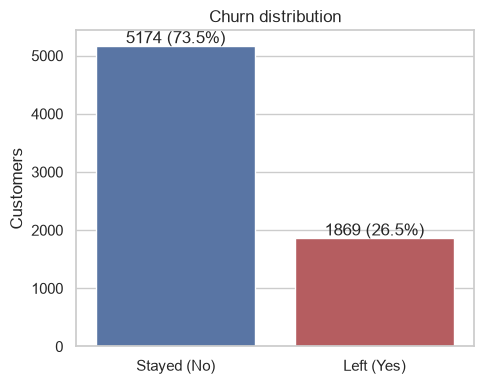

In [5]:
counts = df["Churn"].map({0:"Stayed (No)",1:"Left (Yes)"}).value_counts()
fig, ax = plt.subplots(figsize=(5,4))
sns.barplot(x=counts.index, y=counts.values, palette=["#4C72B0","#C44E52"], ax=ax)
for i,v in enumerate(counts.values): ax.text(i, v+40, f"{v} ({v/len(df):.1%})", ha="center")
ax.set_title("Churn distribution"); ax.set_ylabel("Customers"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(VIS_DIR/"churn_distribution.png", dpi=150); plt.show()

**Interpretation:** about 26.5% of customers churned – moderately imbalanced (~2.8 : 1). Accuracy alone would be misleading (always predicting 'stay' gives ~73.5%), so we report precision, recall, F1, ROC-AUC and PR-AUC, and test `class_weight='balanced'` as an imbalance-handling configuration.

### EDA 2 – Churn rate by categorical features

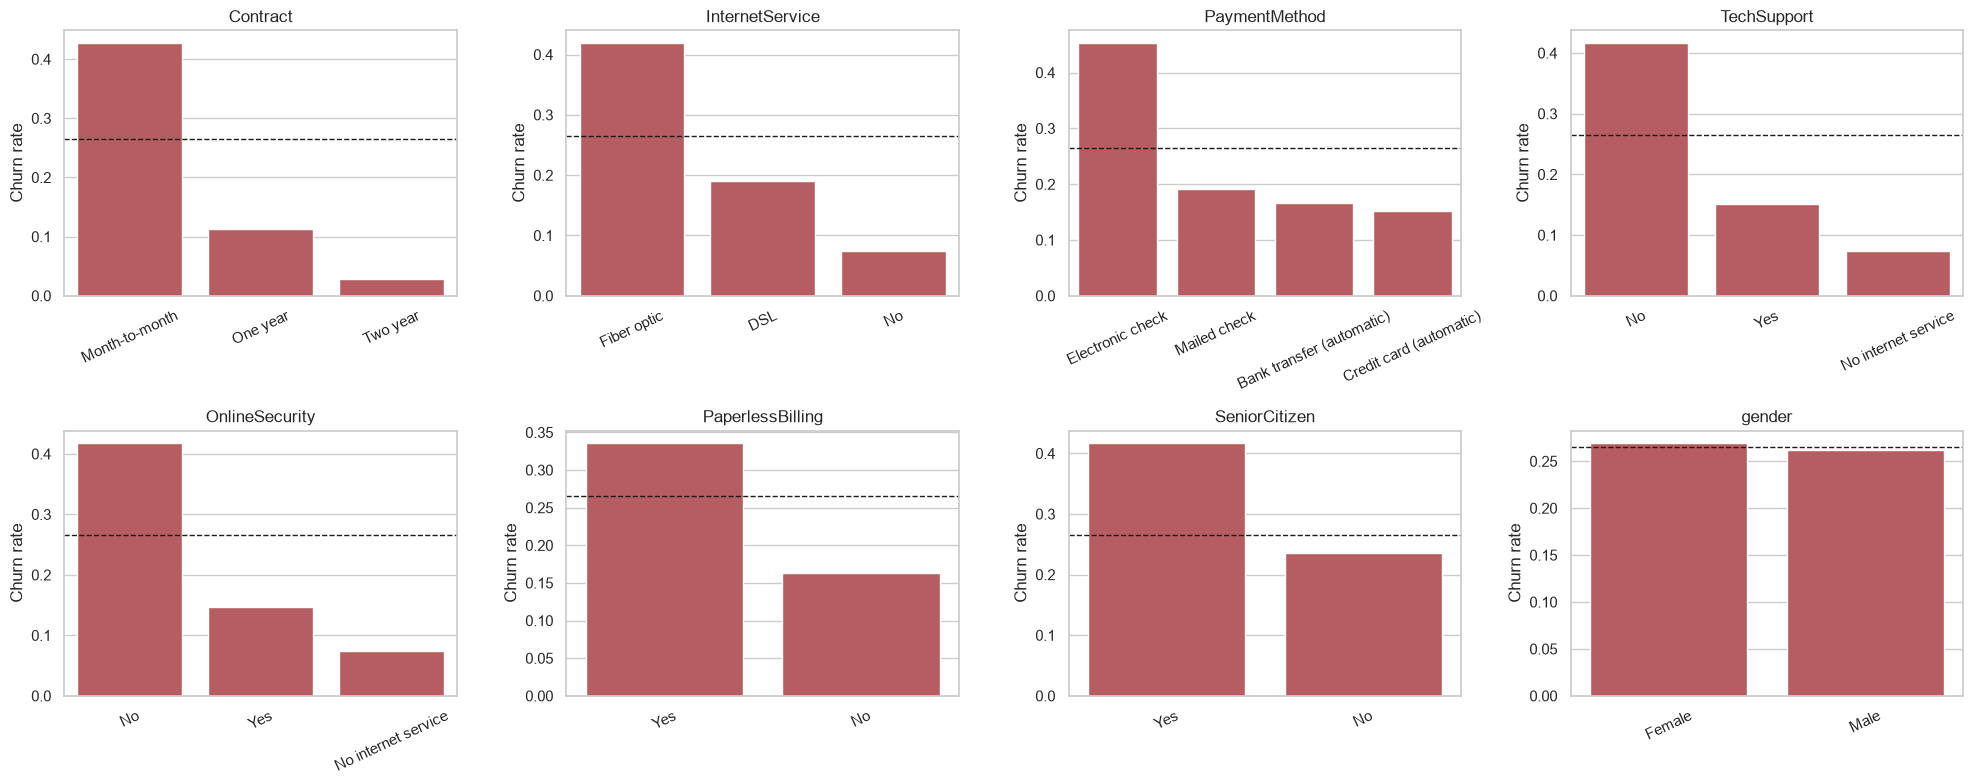

In [6]:
cats = ["Contract","InternetService","PaymentMethod","TechSupport","OnlineSecurity","PaperlessBilling","SeniorCitizen","gender"]
fig, axes = plt.subplots(2,4, figsize=(20,8))
for ax,c in zip(axes.ravel(), cats):
    r = df.groupby(c)["Churn"].mean().sort_values(ascending=False)
    sns.barplot(x=r.index, y=r.values, ax=ax, color="#C44E52")
    ax.axhline(df.Churn.mean(), ls="--", c="k", lw=1); ax.set_title(c); ax.set_ylabel("Churn rate"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.savefig(VIS_DIR/"eda_churn_by_category.png", dpi=150); plt.show()

**Interpretation:** the dashed line is the overall churn rate. Month-to-month contracts, fibre-optic internet, electronic-check payment, and no tech support / online security show clearly higher churn; `gender` shows essentially none. These are *associations* – see the causal caveat in notebook 04.

### EDA 3 – Numeric distributions by churn (+ outliers)

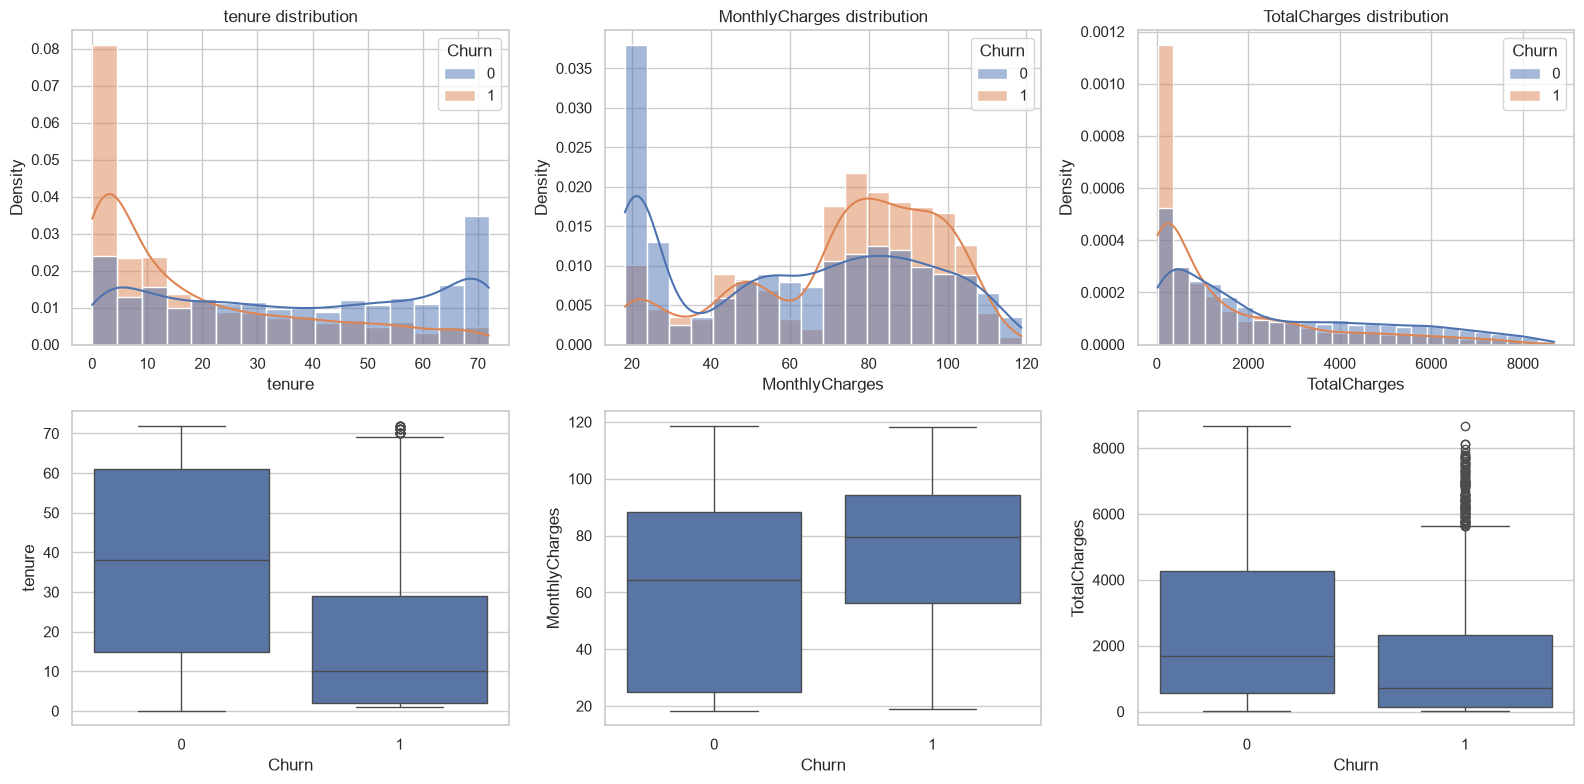

In [7]:
fig, axes = plt.subplots(2,3, figsize=(16,8))
for j,c in enumerate(NUMERIC_COLS):
    sns.histplot(data=df, x=c, hue="Churn", kde=True, stat="density", common_norm=False, ax=axes[0,j])
    sns.boxplot(data=df, x="Churn", y=c, ax=axes[1,j])
    axes[0,j].set_title(f"{c} distribution")
plt.tight_layout(); plt.savefig(VIS_DIR/"eda_numeric_distributions.png", dpi=150); plt.show()

**Interpretation:** churners have much shorter tenure (median far below non-churners) and somewhat higher monthly charges. `TotalCharges` is right-skewed and strongly tied to tenure x monthly charges. Box plots show no extreme erroneous outliers, so no outlier removal is applied (they are real bills).

### EDA 4 – Correlation among numeric features and target

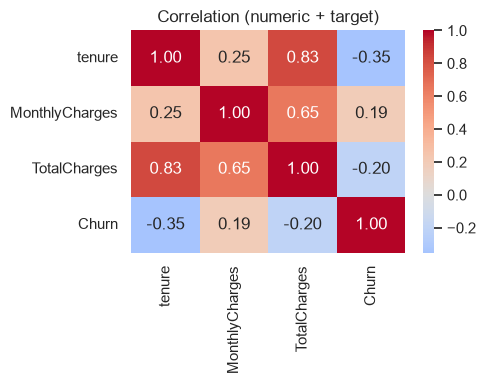

In [8]:
corr = df[NUMERIC_COLS+["Churn"]].corr()
plt.figure(figsize=(5,4)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation (numeric + target)"); plt.tight_layout()
plt.savefig(VIS_DIR/"eda_correlation.png", dpi=150); plt.show()

**Interpretation:** `tenure` and `TotalCharges` are highly correlated (~0.83), so SHAP/LIME importance can be *split* between correlated features – an important caveat for explanation analysis.

## 3. Preprocessing pipeline (documented decisions)

| Step | Decision | Reason |
|---|---|---|
| Drop `customerID` | Yes | Unique identifier, no predictive meaning |
| `TotalCharges` text -> numeric | Yes | 11 blanks (tenure 0) become NaN |
| Missing values | Median imputation, **fit on train only** | Only 11 rows; inside the Pipeline to avoid leakage |
| Binary target | Yes->1, No->0 | |
| Categorical encoding | One-hot (`drop='if_binary'`, `handle_unknown='ignore'`) | No ordinal meaning; keeps features interpretable for SHAP/LIME |
| Scaling | StandardScaler for **Logistic Regression only** | LR needs comparable scales; trees are scale-invariant, so scaling is *unnecessary* for Random Forest and skipped to keep explanations in original units |
| Split | 80/20 stratified, `random_state=42` | Preserves the 26.5% churn rate in both sets |
| Imbalance | No resampling; `class_weight='balanced'` tested as an experiment | Avoids synthetic samples that would distort explanations |

In [9]:
X_train, X_test, y_train, y_test = load_split()
print("Train:", X_train.shape, f"churn={y_train.mean():.3%}")
print("Test :", X_test.shape,  f"churn={y_test.mean():.3%}")

# Demonstrate the pipeline: fit on TRAIN only, transform both
pre = build_preprocessor(X_train, scale=True).fit(X_train)
Xtr_t, Xte_t = pre.transform(X_train), pre.transform(X_test)
print("Features after encoding:", Xtr_t.shape[1])
print("Train-only imputer median TotalCharges:", pre.named_transformers_["num"]["impute"].statistics_[2])
Xtr_t.head()

Train: (5634, 19) churn=26.535%
Test : (1409, 19) churn=26.544%
Features after encoding: 40
Train-only imputer median TotalCharges: 1398.125


,tenure,MonthlyCharges,TotalCharges,gender_Male,SeniorCitizen_Yes,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,...,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0.102371,-0.521976,-0.263290,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3151,-0.711743,0.337478,-0.504815,1.0,0.0,1.0,1.0,1.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4860,-0.793155,-0.809013,-0.751214,1.0,0.0,1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3867,-0.263980,0.284384,-0.173700,0.0,0.0,1.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
3810,-1.281624,-0.676279,-0.990851,1.0,0.0,1.0,1.0,1.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [10]:
# Save the processed feature list for documentation
pd.Series(Xtr_t.columns, name="feature").to_csv(RESULTS_DIR/"encoded_features.csv", index=False)
print(len(Xtr_t.columns), "encoded features saved")

40 encoded features saved
